# Pipeline RAV: detección y corrección de errores médicos en notas clínicas

**Reto MEDIQA-CORR 2024 (dataset MEDEC) · Procesamiento de Lenguaje Natural · Maestría en Inteligencia Artificial**

Cada nota clínica es correcta o contiene **un solo error médico**. El pipeline responde tres preguntas: **A**, si la nota tiene error; **B**, en qué oración está; y **C**, cómo queda la oración corregida.

La idea central es **no pedirle todo a un solo modelo**: un modelo detecta, otro corrige y el primero revisa al segundo. Todos consultan un banco de preguntas médicas (MedQA).

| Sección | Qué hace | Herramienta |
|---|---|---|
| 1. Entendimiento de los datos | Muestra cómo vienen las notas | pandas |
| Caja 1 · Preparar | Une oraciones mal cortadas, marca términos médicos, arma particiones sin fuga | NER biomédico, GroupKFold |
| Caja 2 · Buscar | Trae la pregunta de MedQA más parecida y notas ya resueltas | TF-IDF, similitud coseno |
| Caja 3 · Detectar (A y B) | Califica la sospecha de error de cada oración | BiomedBERT ajustado |
| Caja 4 · Corregir (C) | Propone correcciones candidatas | Qwen2.5-7B-Instruct en 4 bits |
| Caja 5 · Revisar | El detector vuelve a calificar la nota corregida | El mismo BiomedBERT |
| Salida y evaluación | Escribe la entrega y la califica como el reto | ROUGE-1, BERTScore, BLEURT |

Seguimos **un mismo ejemplo** en todas las cajas: un pescador de 53 años con neumonía, cuya nota dice que la causa fue *Haemophilus influenzae* cuando lo correcto era *Streptococcus pneumoniae*.

## 0. Preparación del entorno

El notebook necesita **GPU** (en Colab: *Entorno de ejecución, Cambiar tipo de entorno, T4 GPU*). La segunda celda reúne todos los parámetros en un solo lugar.

In [11]:
# Instalamos las librerías que Colab no trae por defecto.
!pip -q install bitsandbytes accelerate datasets evaluate rouge_score bert_score
!pip -q install git+https://github.com/google-research/bleurt.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [12]:
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import MultinomialNB
from tqdm.auto import tqdm
from transformers import (AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer,
                          BitsAndBytesConfig, DataCollatorWithPadding, Trainer, TrainingArguments, pipeline)

pd.set_option("display.max_colwidth", 120)

# Datos del reto y nota que seguimos como ejemplo.
URL_DATOS = "https://raw.githubusercontent.com/abachaa/MEDEC/main/MEDEC-MS/MEDEC-Full-TrainingSet-with-ErrorType.csv"
URL_MEDQA = "https://huggingface.co/datasets/GBaker/MedQA-USMLE-4-options-hf/resolve/refs%2Fconvert%2Fparquet/default/{}/0000.parquet"
ID_EJEMPLO = "ms-train-0"

# Un modelo de Hugging Face por caja.
MODELO_NER = "d4data/biomedical-ner-all"
MODELO_DETECTOR = "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"
MODELO_LLM = "Qwen/Qwen2.5-7B-Instruct"

# Tamaño de la corrida. Estos valores sirven para una primera prueba rápida.
# Para el resultado final se usa None en los dos primeros y 5 en el tercero.
CASOS_A_USAR = None           # casos clínicos que tomamos del dataset (None = todos)
NOTAS_DE_PRUEBA = None         # notas sobre las que corre el pipeline completo (None = todas)
PARTICIONES_A_EVALUAR = 1    # con 5 se hace la validación cruzada completa

# Parámetros de los modelos.
N_PARTICIONES = 5            # particiones de la validación cruzada
EPOCAS = 3                   # vueltas completas sobre los datos al ajustar el detector
SANAS_POR_NOTA = 3           # oraciones sin error que usamos por nota para entrenar
LONGITUD_MAXIMA = 256        # tokens que lee BERT por ejemplo
N_CANDIDATAS = 4             # correcciones que pedimos al modelo de lenguaje
MAX_PALABRAS_NUEVAS = 6      # una corrección con más palabras nuevas se descarta

SEMILLA = 42
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
print("Dispositivo:", DISPOSITIVO)

Dispositivo: cuda


## 1. Entendimiento de los datos

Cada fila del CSV es una nota clínica en inglés con su texto, sus oraciones numeradas y, si tiene error, la oración equivocada y su versión corregida.

In [13]:
def load_mediqa(path):
    # Esta función lee el CSV del reto. Cuando la nota no tiene error deja -1 como
    # número de oración y "NA" como corrección, que es la convención del reto.
    df = pd.read_csv(path).dropna(subset=["Text"]).reset_index(drop=True)
    df["Error Flag"] = df["Error Flag"].astype(int)
    df["Error Sentence ID"] = df["Error Sentence ID"].fillna(-1).astype(int)
    df["Corrected Sentence"] = df["Corrected Sentence"].fillna("NA")
    return df


df = load_mediqa(URL_DATOS)
print("Notas:", len(df), "| con error:", df["Error Flag"].sum(), "| sin error:", (df["Error Flag"] == 0).sum())

# La nota de ejemplo, campo por campo.
ejemplo = df[df["Text ID"] == ID_EJEMPLO].iloc[0]
ejemplo[["Text ID", "Sentences", "Error Flag", "Error Type", "Error Sentence ID", "Error Sentence", "Corrected Sentence"]].to_frame("valor")

Notas: 2189 | con error: 1219 | sin error: 970


,valor
Text ID,ms-train-0
Sentences,"0 A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and cough..."
Error Flag,1
Error Type,causalOrganism
Error Sentence ID,6
Error Sentence,"After reviewing imaging, the causal pathogen was determined to be Haemophilus influenzae."
Corrected Sentence,"After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae."


Tres gráficos resumen lo que necesitamos saber. Las clases están casi balanceadas, así que responder siempre "hay error" acierta cerca de la mitad de las veces: ese es el piso a superar. Hay cinco tipos de error. Y la oración con error **suele estar hacia el final de la nota**, una pista que el detector va a aprovechar.

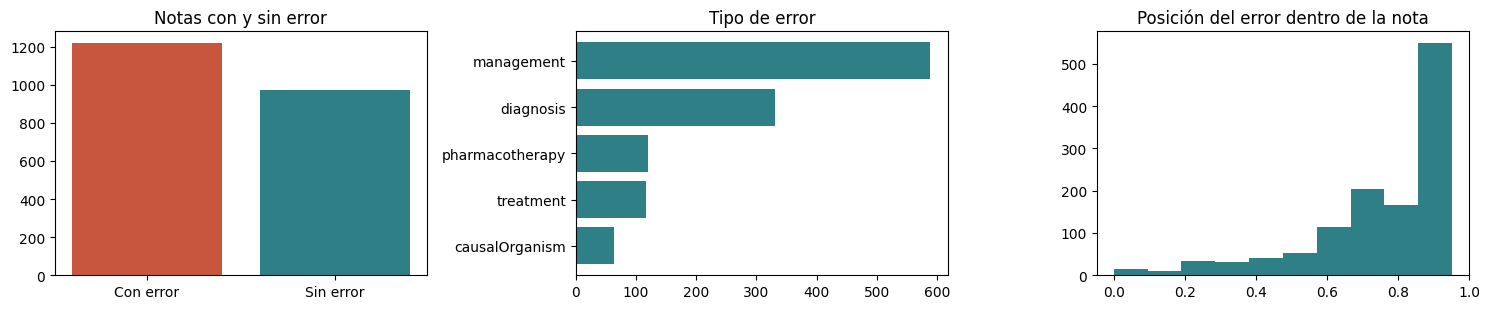

Palabras por nota (mediana): 122 | oraciones por nota (mediana): 11


In [14]:
con_error = df[df["Error Flag"] == 1]
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.2))

# Izquierda: cuántas notas tienen error y cuántas no.
conteo = df["Error Flag"].map({0: "Sin error", 1: "Con error"}).value_counts()
ejes[0].bar(conteo.index, conteo.values, color=["#C8553D", "#2F7F86"])
ejes[0].set_title("Notas con y sin error")

# Centro: los cinco tipos de error.
tipos = con_error["Error Type"].value_counts().sort_values()
ejes[1].barh(tipos.index, tipos.values, color="#2F7F86")
ejes[1].set_title("Tipo de error")

# Derecha: posición de la oración con error (0 = primera oración, 1 = última).
total_oraciones = con_error["Sentences"].str.strip().str.count("\n") + 1
ejes[2].hist(con_error["Error Sentence ID"] / total_oraciones, bins=10, color="#2F7F86")
ejes[2].set_title("Posición del error dentro de la nota")

plt.tight_layout()
plt.show()

print("Palabras por nota (mediana):", int(df["Text"].str.split().str.len().median()),
      "| oraciones por nota (mediana):", int(total_oraciones.median()))

## Caja 1 · Preparar: limpiar antes de trabajar

**Entra:** el CSV del reto. **Sale:** oraciones limpias, términos médicos marcados y 5 particiones sin fuga.

### 1.1 Oraciones

Separamos la nota en oraciones y unimos las que vienen mal cortadas, por ejemplo "98/62 mm" y "Hg." en líneas distintas.

In [15]:
def parse_sentences(sentences):
    # Esta función separa el campo "Sentences" en una lista de oraciones.
    # Cada oración empieza con su número: "0 texto", "1 texto"...
    oraciones = []
    for linea in str(sentences).replace("\r", "").split("\n"):
        linea = linea.strip()
        numero_esperado = str(len(oraciones)) + " "
        if linea.startswith(numero_esperado):
            oraciones.append(linea[len(numero_esperado):].strip())
        elif linea != "" and len(oraciones) > 0:
            oraciones[-1] += " " + linea          # línea sin número: continúa la oración anterior
    return oraciones


def merge_broken_sentences(sentences):
    # Esta función une los cortes falsos y recuerda el número original de cada oración.
    # Unimos una oración con la anterior cuando la anterior no termina en punto
    # y la nueva empieza en minúscula, en un número o en "Hg".
    unidas, numeros = [], []
    for numero, oracion in enumerate(sentences):
        anterior_sin_punto = len(unidas) > 0 and not re.search(r"[.?!][\"')\]]*$", unidas[-1])
        parece_continuacion = re.match(r"[a-z0-9]|Hg", oracion) is not None
        if anterior_sin_punto and parece_continuacion:
            unidas[-1] += " " + oracion
        else:
            unidas.append(oracion)
            numeros.append(numero)
    return unidas, numeros


def locate_error(numeros, error_id):
    # Traduce el número original de la oración con error a su posición en la lista ya unida.
    # Devuelve -1 cuando la nota no tiene error.
    posicion = -1
    for i, numero in enumerate(numeros):
        if 0 <= numero <= error_id:
            posicion = i
    return posicion


# Aplicamos las funciones y guardamos el resultado en columnas nuevas.
crudas = df["Sentences"].apply(parse_sentences)
unidas = crudas.apply(merge_broken_sentences)
df["sentences"] = [u[0] for u in unidas]
df["numeros"] = [u[1] for u in unidas]      # número original de cada oración, lo pide la subtarea B

df["error_idx"] = [locate_error(n, e) for n, e in zip(df["numeros"], df["Error Sentence ID"])]

con_cortes = np.mean([len(a) > len(b) for a, b in zip(crudas, df["sentences"])])
print(f"Notas con oraciones mal cortadas: {con_cortes:.0%}\n")

# En el ejemplo, las líneas 3 y 4 quedan como una sola oración.
ejemplo = df[df["Text ID"] == ID_EJEMPLO].iloc[0]
for numero, oracion in zip(ejemplo["numeros"], ejemplo["sentences"]):
    print(numero, "|", oracion)

Notas con oraciones mal cortadas: 55%

0 | A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and cough with yellow-green sputum.
1 | He works as a commercial fisherman on Lake Superior.
2 | Current medications include metoprolol and warfarin.
3 | His temperature is 38.5 C (101.3 F), pulse is 96/min, respirations are 26/min, and blood pressure is 98/62 mm Hg.
5 | Examination shows increased fremitus and bronchial breath sounds over the right middle lung field.
6 | After reviewing imaging, the causal pathogen was determined to be Haemophilus influenzae.
7 | An x-ray of the chest showed consolidation of the right upper lobe.


### 1.2 Términos médicos

Tomamos un modelo de **Reconocimiento de Entidades Nombradas** ya entrenado en textos biomédicos. Marca en cada oración las enfermedades, los medicamentos y los procedimientos, porque el error casi siempre es uno de esos términos.

In [16]:
# aggregation_strategy junta los pedazos de una palabra para que el término salga completo.
modelo_ner = pipeline("token-classification", model=MODELO_NER, aggregation_strategy="first",
                      device=0 if DISPOSITIVO == "cuda" else -1)

ETIQUETAS_MEDICAS = ["Disease_disorder", "Medication", "Therapeutic_procedure", "Diagnostic_procedure"]


def extract_entities(sentences):
    # Esta función recibe las oraciones de una nota y devuelve los términos médicos de cada una.
    resultados = modelo_ner(list(sentences), batch_size=32)
    return [sorted({e["word"].strip() for e in entidades if e["entity_group"] in ETIQUETAS_MEDICAS})
            for entidades in resultados]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

### 1.3 Particiones sin fuga

Muchos casos aparecen dos veces: una versión correcta y otra con error. Si una queda en entrenamiento y la otra en prueba, el modelo ya habría visto la respuesta. Por eso las dos versiones deben quedar en la misma partición.

In [17]:
def assign_scenario_id(df):
    # Esta función identifica qué notas son el mismo caso clínico.
    # Las dos versiones de un caso empiezan igual, así que usamos el inicio del texto como identificador.
    inicio = df["Text"].str.lower().str.replace(r"\W+", " ", regex=True).str[:100]
    return inicio.factorize()[0]


def make_group_folds(df, n_splits=5):
    # Esta función reparte las notas en particiones.
    # GroupKFold garantiza que las notas de un mismo caso caen en la misma partición.
    particion = np.zeros(len(df), dtype=int)
    for k, (_, prueba) in enumerate(GroupKFold(n_splits=n_splits).split(df, groups=df["scenario_id"])):
        particion[prueba] = k
    return particion


df["scenario_id"] = assign_scenario_id(df)
tamanos = df["scenario_id"].value_counts()
print("Casos distintos:", len(tamanos), "| casos con dos versiones o más:", (tamanos > 1).sum())

# Para la prueba rápida tomamos una muestra de casos (siempre incluimos el del ejemplo).
if CASOS_A_USAR is not None:
    casos = df["scenario_id"].drop_duplicates().sample(CASOS_A_USAR, random_state=SEMILLA).tolist()
    casos.append(df.loc[df["Text ID"] == ID_EJEMPLO, "scenario_id"].iloc[0])
    df = df[df["scenario_id"].isin(casos)].reset_index(drop=True)

df["fold"] = make_group_folds(df, n_splits=N_PARTICIONES)
df["entities"] = [extract_entities(o) for o in tqdm(df["sentences"], desc="Términos médicos")]

print("Notas en uso:", len(df), "| notas por partición:", df["fold"].value_counts().sort_index().tolist())
ejemplo = df[df["Text ID"] == ID_EJEMPLO].iloc[0]
print("Términos de la oración con error del ejemplo:", ejemplo["entities"][ejemplo["error_idx"]])

Casos distintos: 1246 | casos con dos versiones o más: 941


Términos médicos:   0%|          | 0/2189 [00:00<?, ?it/s]

Notas en uso: 2189 | notas por partición: [438, 438, 438, 438, 437]
Términos de la oración con error del ejemplo: []


## Caja 2 · Buscar: consultar el libro en vez de memorizar

**Entra:** la nota limpia. **Sale:** la pregunta de MedQA más parecida con su respuesta, la opción que aparece en la nota y 3 notas resueltas parecidas.

Las notas se construyeron a partir de preguntas del examen médico de Estados Unidos (MedQA). Hacemos lo que haría un estudiante: buscar el ejercicio parecido ya resuelto. La búsqueda usa **TF-IDF y similitud coseno**, los conceptos de la clase de texto en vectores.

In [18]:
def load_medqa():
    # Esta función descarga el banco de preguntas. Cada pregunta trae el enunciado (sent1),
    # cuatro opciones (ending0 a ending3) y el número de la opción correcta (label).
    medqa = pd.concat([pd.read_parquet(URL_MEDQA.format(p)) for p in ["train", "validation", "test"]],
                      ignore_index=True)
    medqa["options"] = medqa[["ending0", "ending1", "ending2", "ending3"]].values.tolist()
    medqa["answer"] = [opciones[correcta] for opciones, correcta in zip(medqa["options"], medqa["label"])]
    return medqa


def build_tfidf_index(texts):
    # Esta función convierte una colección de textos en vectores TF-IDF una sola vez.
    vectorizador = TfidfVectorizer(stop_words="english")
    return vectorizador, vectorizador.fit_transform(texts)


def search(texto, indice, k=1):
    # Devuelve las posiciones de los k textos del índice más parecidos al texto de consulta.
    vectorizador, matriz = indice
    similitud = cosine_similarity(vectorizador.transform([texto]), matriz)[0]
    return similitud.argsort()[::-1][:k]


def retrieve_medqa(note):
    # Esta función trae la pregunta de MedQA más parecida a la nota, con sus opciones y su respuesta.
    pregunta = medqa.iloc[search(note, indice_medqa)[0]]
    return {"options": pregunta["options"], "answer": pregunta["answer"]}


def match_option(sentences, options, answer):
    # Esta función busca si una opción incorrecta de la pregunta aparece escrita en la nota.
    # Si aparece, es una pista fuerte del error. Devuelve la opción y la oración donde está.
    for opcion in options:
        for i, oracion in enumerate(sentences):
            if opcion != answer and len(opcion) > 3 and opcion.lower() in oracion.lower():
                return {"option": opcion, "sentence_idx": i}
    return None


def retrieve_similar_notes(note, banco, k=3):
    # Esta función trae k notas con error ya resueltas y parecidas a la nota actual.
    # El banco solo tiene notas de entrenamiento, para no hacer trampa.
    indice, resueltas = banco
    return resueltas.iloc[search(note, indice, k)][["Error Sentence", "Corrected Sentence"]].values.tolist()


medqa = load_medqa()
indice_medqa = build_tfidf_index(medqa["sent1"])

# La búsqueda en MedQA no depende de la partición, así que la hacemos una vez para todas las notas.
df["medqa"] = [retrieve_medqa(texto) for texto in tqdm(df["Text"], desc="Buscando en MedQA")]
df["match"] = [match_option(o, m["options"], m["answer"]) for o, m in zip(df["sentences"], df["medqa"])]

ejemplo = df[df["Text ID"] == ID_EJEMPLO].iloc[0]
print("Preguntas en MedQA:", len(medqa))
print("Opciones de la pregunta encontrada:", ejemplo["medqa"]["options"])
print("Respuesta correcta:", ejemplo["medqa"]["answer"])
print("Opción incorrecta encontrada en la nota:", ejemplo["match"])

Buscando en MedQA:   0%|          | 0/2189 [00:00<?, ?it/s]

Preguntas en MedQA: 12723
Opciones de la pregunta encontrada: ['Pseudomonas aeruginosa', 'Streptococcus pyogenes', 'Haemophilus influenzae', 'Streptococcus pneumoniae']
Respuesta correcta: Streptococcus pneumoniae
Opción incorrecta encontrada en la nota: {'option': 'Haemophilus influenzae', 'sentence_idx': 5}


## Caja 3 · Detectar: revisar oración por oración (subtareas A y B)

**Entra:** oraciones, términos médicos y pistas de la Caja 2. **Sale:** sospecha por oración, bandera A y oración B.

Es el corazón del pipeline. **BiomedBERT** aprendió el lenguaje médico leyendo millones de artículos. Aquí lo ajustamos para una **clasificación de pares de texto**: recibe una oración junto con el resto de la nota y devuelve una sospecha entre 0 y 1. El modelo no escribe, solo califica.

Si la oración más sospechosa supera un umbral, la nota tiene error (A) y está en esa oración (B). Un solo modelo resuelve las dos subtareas y sus respuestas nunca se contradicen.

In [19]:
tokenizador_bert = AutoTokenizer.from_pretrained(MODELO_DETECTOR)


def build_sentence_pairs(nota):
    # Esta función arma un ejemplo por cada oración de la nota. Cada ejemplo tiene dos textos:
    #   texto_a: la oración que se califica, con su posición y sus términos médicos
    #   texto_b: la respuesta de MedQA y la nota completa, que sirven de contexto
    # La etiqueta es 1 si esa oración es la del error y 0 si no.
    oraciones = nota["sentences"]
    contexto = f"Reference answer: {nota['medqa']['answer']}. Note: {' '.join(oraciones)}"
    return [{"texto_a": f"Sentence {i + 1} of {len(oraciones)}: {oracion} Terms: {'; '.join(nota['entities'][i])}",
             "texto_b": contexto,
             "label": int(i == nota["error_idx"])}
            for i, oracion in enumerate(oraciones)]


def tokenize_pairs(batch):
    # Esta función convierte los pares al formato que entiende BERT.
    # El tokenizador une los dos textos y los corta a LONGITUD_MAXIMA tokens.
    return tokenizador_bert(batch["texto_a"], batch["texto_b"], truncation=True, max_length=LONGITUD_MAXIMA)


def training_pairs(notas):
    # Hay muchas más oraciones sanas que con error. Para que el modelo no aprenda a decir
    # siempre "sin error", de cada nota tomamos la oración con error y solo unas pocas sanas.
    pares = []
    for _, nota in notas.iterrows():
        todos = build_sentence_pairs(nota)
        sanas = [p for p in todos if p["label"] == 0]
        pares += [p for p in todos if p["label"] == 1] + random.sample(sanas, min(SANAS_POR_NOTA, len(sanas)))
    return Dataset.from_list(pares).map(tokenize_pairs, batched=True)


def train_detector(train, val):
    # Esta función ajusta BiomedBERT. Trainer se encarga del ciclo de entrenamiento:
    # predecir, medir el error y corregir los pesos del modelo, lote por lote.
    modelo = AutoModelForSequenceClassification.from_pretrained(MODELO_DETECTOR, num_labels=2)
    argumentos = TrainingArguments(output_dir="detector", num_train_epochs=EPOCAS, learning_rate=2e-5,
                                   per_device_train_batch_size=16, per_device_eval_batch_size=32,
                                   eval_strategy="epoch", save_strategy="no", report_to="none", seed=SEMILLA)
    entrenador = Trainer(model=modelo, args=argumentos, train_dataset=train, eval_dataset=val,
                         data_collator=DataCollatorWithPadding(tokenizador_bert))
    entrenador.train()
    return modelo.eval()


# Así se ve el ejemplo que corresponde a la oración con error de nuestra nota.
par = build_sentence_pairs(ejemplo)[ejemplo["error_idx"]]
print("texto_a:", par["texto_a"])
print("texto_b:", par["texto_b"][:160], "...")
print("label  :", par["label"])

texto_a: Sentence 6 of 7: After reviewing imaging, the causal pathogen was determined to be Haemophilus influenzae. Terms: 
texto_b: Reference answer: Streptococcus pneumoniae. Note: A 53-year-old man comes to the physician because of a 1-day history of fever and chills, severe malaise, and c ...
label  : 1


Con el modelo ajustado calculamos la sospecha de cada oración. Falta decidir desde qué valor decimos "hay error". Ese valor es el **umbral** y lo escogemos con notas que el modelo no usó para aprender.

In [20]:
def score_sentences(model, nota):
    # Esta función calcula la sospecha (probabilidad de error) de cada oración de una nota.
    pares = build_sentence_pairs(nota)
    entradas = tokenizador_bert([p["texto_a"] for p in pares], [p["texto_b"] for p in pares], truncation=True,
                                max_length=LONGITUD_MAXIMA, padding=True, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probabilidades = torch.softmax(model(**entradas).logits, dim=1)
    return probabilidades[:, 1].tolist()


def calibrate_threshold(scores, labels):
    # Esta función prueba varios umbrales y escoge el que más aciertos da en la subtarea A.
    # scores es la sospecha máxima de cada nota y labels dice si la nota tiene error.
    umbrales = np.arange(0.05, 1.0, 0.05)
    aciertos = [np.mean((np.array(scores) > u) == np.array(labels)) for u in umbrales]
    return float(umbrales[np.argmax(aciertos)])


def predict_flag_and_sentence(scores, threshold):
    # Esta función decide A y B: si la oración más sospechosa supera el umbral,
    # hay error y está en esa oración.
    mas_sospechosa = int(np.argmax(scores))
    if scores[mas_sospechosa] > threshold:
        return 1, mas_sospechosa
    return 0, -1


def fit_partition(k):
    # Esta función prepara la partición k. Sus notas quedan como prueba y no se tocan.
    # La partición siguiente sirve para calibrar el umbral y las otras tres para entrenar.
    k_calibracion = (k + 1) % N_PARTICIONES
    prueba = df[df["fold"] == k]
    calibracion = df[df["fold"] == k_calibracion]
    entrenamiento = df[~df["fold"].isin([k, k_calibracion])]

    detector = train_detector(training_pairs(entrenamiento), training_pairs(calibracion))

    sospecha_maxima = [max(score_sentences(detector, nota)) for _, nota in calibracion.iterrows()]
    umbral = calibrate_threshold(sospecha_maxima, calibracion["Error Flag"])

    # Banco de notas resueltas para la Caja 4: solo notas de entrenamiento con error.
    resueltas = entrenamiento[entrenamiento["Error Flag"] == 1]
    banco = (build_tfidf_index(resueltas["Text"]), resueltas)

    return {"detector": detector, "umbral": umbral, "banco": banco, "prueba": prueba.head(NOTAS_DE_PRUEBA)}


# Preparamos la partición donde cayó la nota de ejemplo, así el detector nunca la vio al entrenar.
particion_ejemplo = int(ejemplo["fold"])
ajuste = fit_partition(particion_ejemplo)
detector, umbral = ajuste["detector"], ajuste["umbral"]
print("Umbral escogido:", round(umbral, 2))

Map:   0%|          | 0/4650 [00:00<?, ? examples/s]

Map:   0%|          | 0/1556 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect ide

Epoch,Training Loss,Validation Loss
1,No log,0.075978
2,0.115054,0.072540
3,0.115054,0.085982


Umbral escogido: 0.05


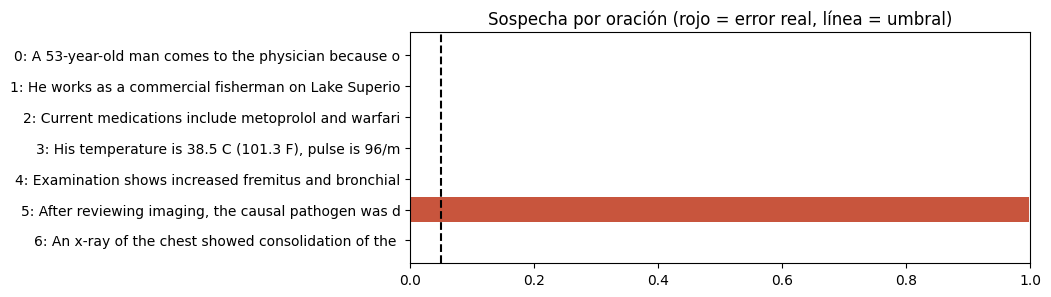

Subtarea A, ¿hay error?: 1 | real: 1
Subtarea B, ¿qué oración?: 5 | real: 5


In [21]:
# Resultado en la nota de ejemplo: la sospecha de cada oración y la decisión.
sospechas = score_sentences(detector, ejemplo)
bandera, oracion_idx = predict_flag_and_sentence(sospechas, umbral)

etiquetas = [f"{i}: {o[:50]}" for i, o in enumerate(ejemplo["sentences"])]
colores = ["#C8553D" if i == ejemplo["error_idx"] else "#2F7F86" for i in range(len(sospechas))]

plt.figure(figsize=(8, 3))
plt.barh(etiquetas[::-1], sospechas[::-1], color=colores[::-1])
plt.axvline(umbral, color="black", linestyle="--")
plt.xlim(0, 1)
plt.title("Sospecha por oración (rojo = error real, línea = umbral)")
plt.show()

print("Subtarea A, ¿hay error?:", bandera, "| real:", ejemplo["Error Flag"])
print("Subtarea B, ¿qué oración?:", oracion_idx, "| real:", ejemplo["error_idx"])

## Caja 4 · Corregir: el especialista propone (subtarea C)

**Entra:** la nota, la oración sospechosa, la respuesta de MedQA y 3 ejemplos. **Sale:** de 3 a 5 correcciones candidatas.

Aquí sí necesitamos un modelo que escriba, es decir, una tarea de **generación de lenguaje**. Usamos **Qwen2.5-7B-Instruct**, un modelo abierto de 7 mil millones de parámetros cargado en 4 bits para que quepa en la GPU de Colab. Solo se usa cuando la Caja 3 encontró un error, y le pedimos cambiar **solo el término equivocado**.

In [22]:
# La configuración de 4 bits reduce la memoria que ocupa cada parámetro del modelo.
configuracion_4bits = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
tokenizador_llm = AutoTokenizer.from_pretrained(MODELO_LLM)
llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, quantization_config=configuracion_4bits, device_map="auto")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

In [23]:
def build_prompt(note, sentence, medqa, examples):
    # Esta función arma la instrucción: primero los ejemplos resueltos y luego el caso a corregir.
    texto = ("One sentence of this clinical note has a medical error. Rewrite only that sentence so it is "
             "medically correct. Change as few words as possible. Answer with the corrected sentence only.\n\n")
    for con_error, corregida in examples:
        texto += f"Sentence with error: {con_error}\nCorrected sentence: {corregida}\n\n"
    texto += (f"Clinical note: {note}\nAnswer to a similar exam question: {medqa['answer']}\n"
              f"Sentence with error: {sentence}\nCorrected sentence:")
    return [{"role": "user", "content": texto}]


def generate_candidates(prompt, n=4):
    # Esta función le pide al modelo n correcciones distintas.
    # do_sample activa el muestreo para que las respuestas varíen y temperature controla cuánto.
    entradas = tokenizador_llm.apply_chat_template(prompt, add_generation_prompt=True, return_dict=True,
                                                   return_tensors="pt").to(llm.device)
    salida = llm.generate(**entradas, max_new_tokens=80, do_sample=True, temperature=0.8,
                          num_return_sequences=n, pad_token_id=tokenizador_llm.eos_token_id)

    # Nos quedamos con lo que el modelo escribió después de la instrucción, solo la primera línea.
    nuevos = salida[:, entradas["input_ids"].shape[1]:]
    textos = tokenizador_llm.batch_decode(nuevos, skip_special_tokens=True)
    return [t.strip().split("\n")[0].strip('" ') for t in textos]


def add_medqa_candidate(sentence, match, answer):
    # Esta función crea la candidata directa: si la oración contiene la opción incorrecta
    # de MedQA, la cambia por la respuesta correcta.
    if match is None:
        return sentence
    return re.sub(re.escape(match["option"]), lambda m: answer, sentence, flags=re.IGNORECASE)


def keep_minimal_edits(sentence, candidates):
    # Esta función descarta las candidatas repetidas, iguales a la original
    # o que agregan demasiadas palabras nuevas.
    originales = set(sentence.split())
    aceptadas = []
    for c in candidates:
        palabras_nuevas = sum(palabra not in originales for palabra in c.split())
        if c != "" and c != sentence and c not in aceptadas and palabras_nuevas <= MAX_PALABRAS_NUEVAS:
            aceptadas.append(c)
    return aceptadas


def propose_corrections(nota, oracion_idx, banco):
    # Esta función reúne los pasos de la Caja 4 para una nota.
    oracion = nota["sentences"][oracion_idx]
    ejemplos = retrieve_similar_notes(nota["Text"], banco, k=3)
    prompt = build_prompt(" ".join(nota["sentences"]), oracion, nota["medqa"], ejemplos)

    candidatas = generate_candidates(prompt, n=N_CANDIDATAS)
    candidatas.append(add_medqa_candidate(oracion, nota["match"], nota["medqa"]["answer"]))
    return keep_minimal_edits(oracion, candidatas)


# Candidatas para la oración más sospechosa de la nota de ejemplo.
idx_sospechosa = int(np.argmax(sospechas))
candidatas = propose_corrections(ejemplo, idx_sospechosa, ajuste["banco"])

print("Oración sospechosa:", ejemplo["sentences"][idx_sospechosa])
for c in candidatas:
    print("  candidata:", c)

Oración sospechosa: After reviewing imaging, the causal pathogen was determined to be Haemophilus influenzae.
  candidata: After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.


## Caja 5 · Revisar: la segunda opinión

**Entra:** las correcciones candidatas. **Sale:** la corrección final (C) o el retiro de la alarma.

No confiamos ciegamente en el corrector. Cada candidata se pone en la nota y la nota corregida **vuelve a pasar por el detector de la Caja 3**. Si con alguna candidata la nota deja de ser sospechosa, esa es la respuesta. Si ninguna lo logra, concluimos que el detector se equivocó y retiramos la alarma. No se entrena ningún modelo nuevo.

In [24]:
def apply_candidate(nota, sentence_id, candidate):
    # Esta función devuelve una copia de la nota con la oración reemplazada por la candidata.
    nueva = nota.copy()
    nueva["sentences"] = nota["sentences"][:sentence_id] + [candidate] + nota["sentences"][sentence_id + 1:]
    nueva["entities"] = extract_entities(nueva["sentences"])
    return nueva


def rescore_note(model, nota):
    # Esta función vuelve a calcular la sospecha máxima de la nota.
    return max(score_sentences(model, nota))


def select_best_candidate(candidates, scores, threshold):
    # Esta función escoge la candidata que deja la sospecha más baja,
    # siempre que la nota deje de superar el umbral. Si ninguna sirve devuelve None.
    if len(candidates) > 0 and min(scores) <= threshold:
        return candidates[int(np.argmin(scores))]
    return None


def retract_alarm(prediction):
    # Esta función retira la alarma: la nota se reporta como correcta.
    prediction.update({"flag": 0, "sentence_id": -1, "correction": "NA"})
    return prediction


# Revisamos las candidatas de la nota de ejemplo.
sospechas_nuevas = [rescore_note(detector, apply_candidate(ejemplo, idx_sospechosa, c)) for c in candidatas]

print(f"Sospecha máxima de la nota original: {max(sospechas):.2f} | umbral: {umbral:.2f}")
for c, s in zip(candidatas, sospechas_nuevas):
    print(f"  {s:.2f} | {c}")
print("\nCorrección escogida:", select_best_candidate(candidatas, sospechas_nuevas, umbral))
print("Corrección oficial :", ejemplo["Corrected Sentence"])

Sospecha máxima de la nota original: 1.00 | umbral: 0.05
  0.00 | After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.

Corrección escogida: After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.
Corrección oficial : After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.


## Salida y evaluación: calificar como el reto

**Entra:** las predicciones. **Sale:** el archivo de entrega y la tabla de resultados.

La función `run_pipeline` encadena las Cajas 3, 4 y 5. Es la **instancia** del pipeline: recibe una nota preparada y devuelve las tres respuestas.

In [25]:
def run_pipeline(nota, ajuste):
    detector, umbral = ajuste["detector"], ajuste["umbral"]
    prediccion = {"Text ID": nota["Text ID"], "flag": 0, "sentence_id": -1, "correction": "NA"}

    # Caja 3. Si ninguna oración supera el umbral, la nota sale como correcta sin usar el modelo de lenguaje.
    bandera, oracion_idx = predict_flag_and_sentence(score_sentences(detector, nota), umbral)
    if bandera == 0:
        return prediccion

    # Caja 4. Correcciones candidatas para la oración sospechosa.
    candidatas = propose_corrections(nota, oracion_idx, ajuste["banco"])

    # Caja 5. El detector revisa cada candidata y escoge una o retira la alarma.
    sospechas_nuevas = [rescore_note(detector, apply_candidate(nota, oracion_idx, c)) for c in candidatas]
    mejor = select_best_candidate(candidatas, sospechas_nuevas, umbral)
    if mejor is None:
        return retract_alarm(prediccion)

    # El reto pide el número original de la oración, que guardamos en la Caja 1.
    prediccion.update({"flag": 1, "sentence_id": nota["numeros"][oracion_idx], "correction": mejor})
    return prediccion


# Demostración con la nota de ejemplo.
run_pipeline(ejemplo, ajuste)

{'Text ID': 'ms-train-0',
 'flag': 1,
 'sentence_id': 6,
 'correction': 'After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.'}

Las subtareas A y B se miden con **porcentaje de aciertos**. La subtarea C compara la corrección propuesta con la oficial: **ROUGE-1** mide las palabras que comparten, y **BERTScore** y **BLEURT** miden si significan lo mismo. Seguimos la regla del reto: si la nota no tenía error y el sistema respondió NA vale 1, y si solo uno de los dos es NA vale 0.

Como punto de comparación entrenamos una **línea base**: Bayes ingenuo sobre TF-IDF para la subtarea A.

In [29]:
import evaluate

rouge = evaluate.load("rouge")
bertscore = evaluate.load("bertscore")
try:
    # BLEURT usa TensorFlow. Lo dejamos en CPU para que no compita por la memoria de la GPU.
    import tensorflow as tf
    tf.config.set_visible_devices([], "GPU")
    bleurt = evaluate.load("bleurt", "BLEURT-20")
except Exception as error:
    bleurt = None
    print("BLEURT no está disponible, seguimos con ROUGE-1 y BERTScore. Detalle:", error)


def eval_accuracy(y, y_pred):
    # Porcentaje de aciertos: en cuántas notas la predicción es igual a la referencia.
    return float(np.mean(np.array(y) == np.array(y_pred)))


def eval_correction(references, predictions):
    # Esta función califica la subtarea C. Las métricas de texto solo se calculan
    # en las notas donde hay corrección oficial y también corrección propuesta.
    aciertos_na = sum(r == "NA" and p == "NA" for r, p in zip(references, predictions))
    refs = [r for r, p in zip(references, predictions) if r != "NA" and p != "NA"]
    preds = [p for r, p in zip(references, predictions) if r != "NA" and p != "NA"]

    puntajes = {}
    if len(refs) > 0:
        puntajes["ROUGE-1"] = rouge.compute(predictions=preds, references=refs, use_aggregator=False)["rouge1"]
        # Se cambia el modelo a distilbert-base-uncased para evitar el OverflowError y acelerar la evaluación
        puntajes["BERTScore"] = bertscore.compute(predictions=preds, references=refs, lang="en",
                                                  model_type="distilbert-base-uncased")["f1"]
        if bleurt is not None:
            puntajes["BLEURT"] = bleurt.compute(predictions=preds, references=refs)["scores"]

    # Cada métrica se limita al rango de 0 a 1, se le suman los NA acertados y se divide entre todas las notas.
    resultado = {nombre: (np.clip(valores, 0, 1).sum() + aciertos_na) / len(references)
                 for nombre, valores in puntajes.items()}
    resultado["Promedio C"] = float(np.mean(list(resultado.values()))) if resultado else aciertos_na / len(references)
    return resultado


def format_submission(predictions, path="prediccion.txt"):
    # Esta función escribe la entrega oficial: una línea por nota con ID, bandera, oración y corrección.
    with open(path, "w", encoding="utf-8") as archivo:
        for _, p in predictions.iterrows():
            archivo.write(f"{p['Text ID']} {p['flag']} {p['sentence_id']} {p['correction']}\n")


def train_baseline(df_train):
    # Línea base: TF-IDF convierte la nota en vector y Bayes ingenuo la clasifica.
    vectorizador = TfidfVectorizer()
    clasificador = MultinomialNB().fit(vectorizador.fit_transform(df_train["Text"]), df_train["Error Flag"])
    return vectorizador, clasificador


def eval_baseline(modelo, df_test):
    vectorizador, clasificador = modelo
    return eval_accuracy(df_test["Error Flag"], clasificador.predict(vectorizador.transform(df_test["Text"])))


In [30]:
def evaluate_folds(particiones, ajustes):
    # Esta función corre el pipeline sobre las notas de prueba de cada partición y reúne los resultados.
    filas, todas = [], []
    for k in particiones:
        if k not in ajustes:
            ajustes[k] = fit_partition(k)         # una partición nueva necesita su propio detector
        prueba = ajustes[k]["prueba"]

        predicciones = pd.DataFrame([run_pipeline(nota, ajustes[k])
                                     for _, nota in tqdm(prueba.iterrows(), total=len(prueba), desc=f"Partición {k}")])
        todas.append(predicciones)

        fila = {"partición": k,
                "Base A (Bayes ingenuo)": eval_baseline(train_baseline(df[df["fold"] != k]), prueba),
                "A": eval_accuracy(prueba["Error Flag"], predicciones["flag"]),
                "B": eval_accuracy(prueba["Error Sentence ID"], predicciones["sentence_id"])}
        fila.update(eval_correction(prueba["Corrected Sentence"].tolist(), predicciones["correction"].tolist()))
        filas.append(fila)
    return pd.DataFrame(filas), pd.concat(todas, ignore_index=True)


# Empezamos por la partición del ejemplo, que ya está preparada.
particiones = [(particion_ejemplo + i) % N_PARTICIONES for i in range(PARTICIONES_A_EVALUAR)]
resultados, predicciones = evaluate_folds(particiones, {particion_ejemplo: ajuste})
format_submission(predicciones)

# La última fila es el promedio de las particiones evaluadas.
resultados.loc["promedio"] = resultados.mean()
resultados.drop(columns="partición").round(3)

Partición 4:   0%|          | 0/437 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Base A (Bayes ingenuo),A,B,ROUGE-1,BERTScore,BLEURT,Promedio C
0,0.551,0.796,0.794,0.767,0.79,0.758,0.772
promedio,0.551,0.796,0.794,0.767,0.79,0.758,0.772


**Lectura de los resultados.** *Base A* es el piso que logra un modelo clásico que solo cuenta palabras. *B* siempre es menor o igual que *A*, porque además de detectar el error hay que ubicarlo. *Promedio C* combina las métricas de texto de la corrección. Como referencia, el artículo de MEDEC reporta 70,2 % en A para el mejor modelo de lenguaje con un solo prompt y el equipo ganador del reto (WangLab) alcanzó 86,5 %, ambos sobre el conjunto de prueba oficial.

La última celda muestra algunas predicciones junto a su corrección oficial.

In [31]:
revision = predicciones.merge(df[["Text ID", "Error Flag", "Error Sentence ID", "Corrected Sentence"]], on="Text ID")
revision[revision["flag"] == 1][["Text ID", "Error Flag", "Error Sentence ID", "sentence_id", "correction", "Corrected Sentence"]].head(8)

,Text ID,Error Flag,Error Sentence ID,sentence_id,correction,Corrected Sentence
0,ms-train-0,1,6,6,"After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae.","After reviewing imaging, the causal pathogen was determined to be Streptococcus pneumoniae."
2,ms-train-4,1,3,3,Causal organism is Staphylococcus aureus.,Causal organism is Staphylococcus aureus.
6,ms-train-13,1,5,5,Further evaluation reveals Chlamydia trachomatis as the causal pathogen.,Further evaluation reveals chlamydia trachomatis as the causal pathogen.
9,ms-train-37,1,0,0,A 28-year-old woman with suspected Escherichia coli infection comes to the physician because of a 4-day history of l...,A 28-year-old woman with suspected Escherichia coli infection comes to the physician because of a 4-day history of l...
10,ms-train-43,1,14,14,Pathology report indicates infection by Bartonella henselae.,Pathology report indicates infection Bartonella henselae.
12,ms-train-55,1,6,6,Lab studies confirm Coccidioides immitis as the causal pathogen.,Lab studies confirm Coccidioides immitis as the causal pathogen.
15,ms-train-77,1,6,6,Patient was diagnosed with a parainfluenza virus infection.,Patient was diagnosed with a parainfluenza virus infection.
16,ms-train-80,1,10,10,STD is discussed and a viral culture and PCR testing is ordered for Haemophilus ducreyi.,STD is discussed and a viral culture and PCR testing is ordered for Haemophilus ducreyi.
